# QUOPS Benchmark

Runs the formal QUOPS benchmark procedure (Supplementary Section V) on Qiskit or CUDA-Q:
- Shapes (width, depth) visited in increasing size within the utility cone
- Bootstrap lower bound must clear 1/sqrt(e) at each shape
- Familywise significance budget (5%) controls false positives
- Reports Q (capability score) and Omega (throughput rate)

Set the app and execution settings below, then run `quops_benchmark.run()`. The run is saved to `__data/<backend_id>/QUOPS-results.json`; the plots are drawn from that file, shown here and saved to `__images/<backend_id>/`.
Set `api = "cudaq"` to run CUDA-Q (in a CUDA-Q container's Jupyter); the default is Qiskit.
With the default depolarizing noise both give Q = 36 at (w=5, s=36), in about 20 s (Qiskit) or 10 s (CUDA-Q `nvidia`).
The same run from the command line, in this folder: `python quops_benchmark.py` (add `-a cudaq` for CUDA-Q).


In [1]:
from qedcbench.quops import quops_benchmark

# Benchmark application settings: the shape sweep
app_args = dict(
    min_qubits = 2,
    max_qubits = 6,
    skip_qubits = 1,            # step between widths
    max_depth = None,           # largest depth (layer pairs) per width; None = 3 x width, 0 = whole utility cone
    max_circuits = 10,          # random circuits per shape
    num_mirrors = 4,            # mirror samples per circuit
    num_shots = 1000,
    noise = "depolarizing",     # p1=0.002, p2=0.05; "none" = noiseless (every shape passes, Q = max_qubits**3)
    max_failures = 1,           # failed shapes before the scan stops (1 = the paper's method)
)

In [2]:
# API: qiskit (default) or cudaq
api = "qiskit"
# api = "cudaq"

if api == "cudaq":
    exec_args = dict(
        api = "cudaq",
        backend_id = "nvidia",       # GPU; with noise it uses trajectories (fast)
        # backend_id = "density-matrix-cpu",   # exact noise on the CPU (~80 s)
        compile_once = True,         # False: a new kernel per circuit, as in PRAQTICE (same results, ~100x slower)
    )
else:
    exec_args = dict(
        api = "qiskit",
        backend_id = None,           # Qiskit always runs Aer; this only names the image folder
    )

print(exec_args)

{'api': 'qiskit', 'backend_id': None}


QUOPS Benchmark - Qiskit Aer 0.17.2 (Qiskit 2.5.0)
Scanning up to 40 shapes (depth <= 3 x width), stopping after 1 failure


w= 2 s=   4 zeta=1.00  lambda=0.9448 lower=0.9403  PASS


w= 2 s=   8 zeta=1.00  lambda=0.8957 lower=0.8885  PASS


w= 3 s=  10 zeta=1.00  lambda=0.8994 lower=0.8921  PASS


w= 3 s=  15 zeta=1.00  lambda=0.8607 lower=0.8508  PASS


...

w= 5 s=  36 zeta=1.00  lambda=0.6577 lower=0.6477  PASS


w= 6 s=  36 zeta=1.00  lambda=0.6444 lower=0.6289  PASS


w= 4 s=  40 zeta=1.00  lambda=0.6051 lower=0.5911  FAIL

QUOPS Q = 36 at (w=5, s=36)
Omega = 3.03e+06 (simulator wall-clock throughput, not a hardware rate)
significance consumed: 0.050 of 0.05
Capability region: [(2, 4), (2, 8), (3, 10), (3, 15), (3, 20), (3, 25), (4, 16), (4, 24), (4, 32), (5, 27), (5, 36), (6, 36)]
... saved C:\Dropbox\Common\github-tl\qcwork\apps\QC-App-Oriented-Benchmarks-master\qedcbench\quops\__data\qasm_simulator\QUOPS-results.json


... saved C:\Dropbox\Common\github-tl\qcwork\apps\QC-App-Oriented-Benchmarks-master\qedcbench\quops\__images\qasm_simulator\QUOPS-shape-scan.jpg
... saved C:\Dropbox\Common\github-tl\qcwork\apps\QC-App-Oriented-Benchmarks-master\qedcbench\quops\__images\qasm_simulator\QUOPS-shape-scan.pdf


... saved C:\Dropbox\Common\github-tl\qcwork\apps\QC-App-Oriented-Benchmarks-master\qedcbench\quops\__images\qasm_simulator\QUOPS-polarization.jpg
... saved C:\Dropbox\Common\github-tl\qcwork\apps\QC-App-Oriented-Benchmarks-master\qedcbench\quops\__images\qasm_simulator\QUOPS-polarization.pdf


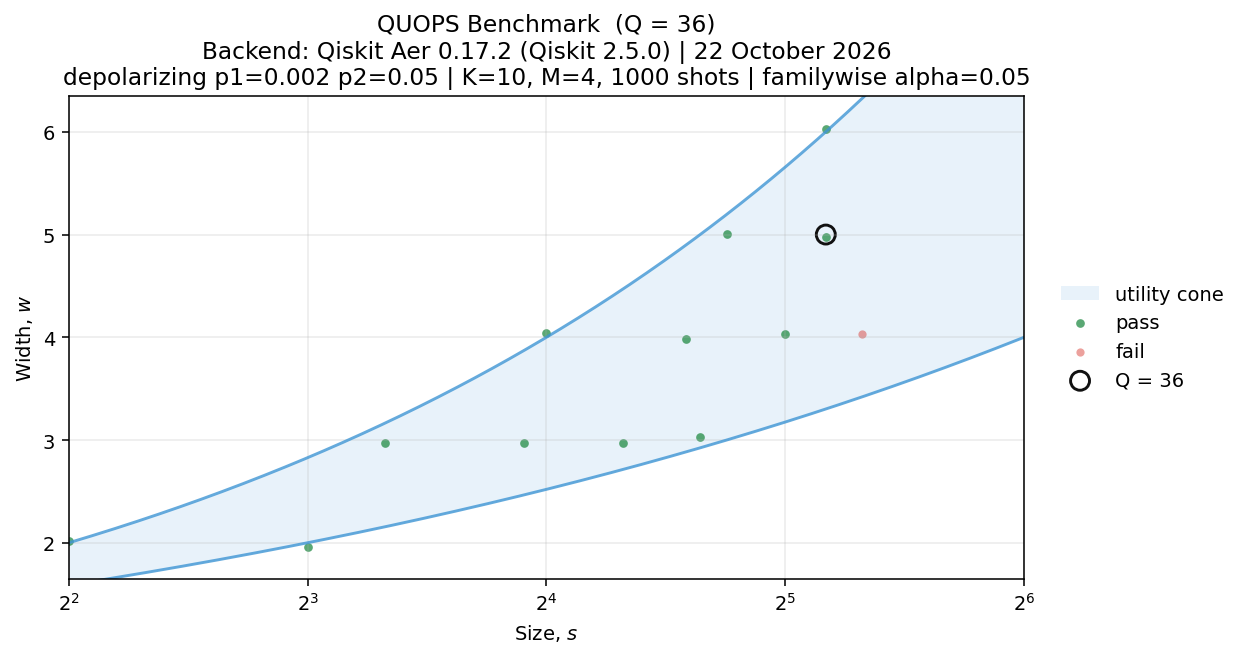

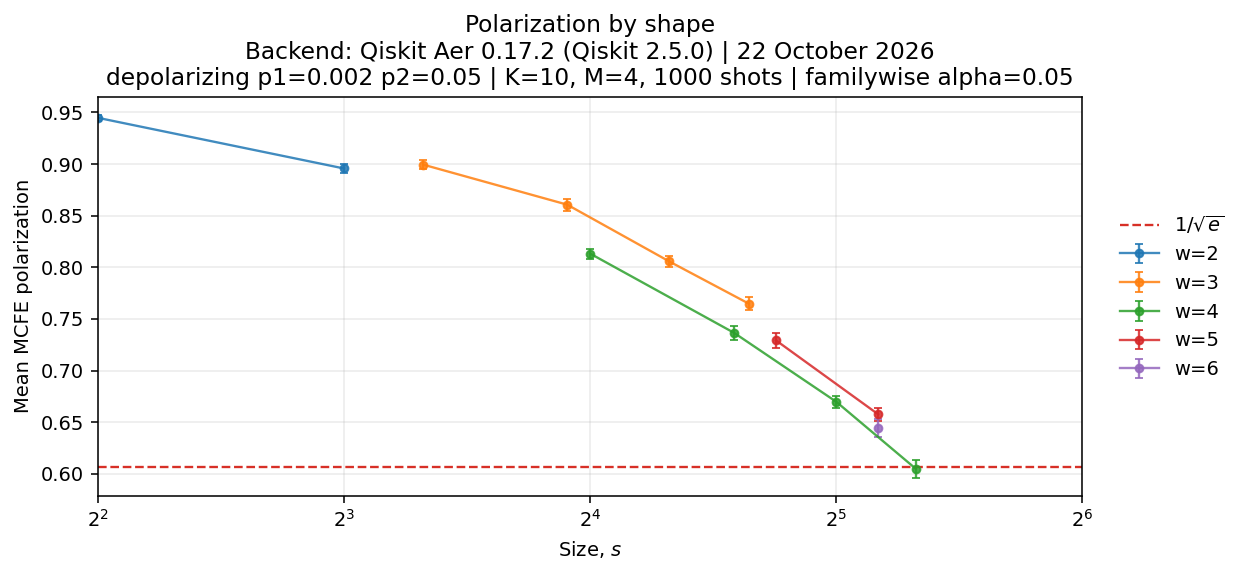

In [3]:
result = quops_benchmark.run(**app_args, **exec_args)

In [4]:
result.summary[["width", "size", "depth", "mean_polarization", "bootstrap_lower",
                "bootstrap_stderr", "passes", "tau_wall"]]

,width,size,depth,mean_polarization,bootstrap_lower,bootstrap_stderr,passes,tau_wall
0,2,4,1,0.944807,0.940296,0.002709,True,0.446761
1,2,8,2,0.895733,0.888547,0.004343,True,0.463334
2,3,10,2,0.899442,0.892069,0.004367,True,0.536847
3,3,15,3,0.860681,0.850777,0.005832,True,0.631227
4,3,20,4,0.805638,0.796788,0.005326,True,0.649145
5,3,25,5,0.764912,0.755064,0.005968,True,0.674875
6,4,16,2,0.813298,0.805234,0.004884,True,0.652010
7,4,24,3,0.736518,0.725343,0.006938,True,0.686938
8,4,32,4,0.669765,0.659411,0.005894,True,0.727472
9,4,40,5,0.605098,0.591097,0.008721,False,0.773308


To remake the plots later from the saved data (no simulator needed), call `plot_results` with the backend the run was saved under; `load_data` returns the result itself.

In [5]:
# quops_benchmark.plot_results(exec_args["backend_id"], api=api)
# result, run_info = quops_benchmark.load_data(exec_args["backend_id"] or "qasm_simulator")